In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('names.txt', 'r').read().splitlines()
words[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [3]:
len(words)

32033

In [4]:
# build teh vacabulory of character and mapping to/from intergers

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(vocab_size)
print(itos)

27
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [5]:
# build the dataset

block_size = 3

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0]*block_size
    for ch in w+'.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  return X, Y

import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

print(Xtr.shape, Ytr.shape)
print(Xdev.shape, Ydev.shape)
print(Xte.shape, Yte.shape)

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
# MLP

n_emb = 10
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g)
b2 = torch.randn(vocab_size, generator=g)

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True

print(sum(p.nelement() for p in parameters))

11897


In [7]:
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

0/200000: 27.8817
10000/200000: 2.9415
20000/200000: 2.5069
30000/200000: 2.7998
40000/200000: 2.0261
50000/200000: 2.5863
60000/200000: 2.3420
70000/200000: 2.0952
80000/200000: 2.3454
90000/200000: 2.2365
100000/200000: 2.1080
110000/200000: 2.3831
120000/200000: 1.9898
130000/200000: 2.4591
140000/200000: 2.1910
150000/200000: 2.1606
160000/200000: 2.1811
170000/200000: 1.7997
180000/200000: 2.0962
190000/200000: 1.8052


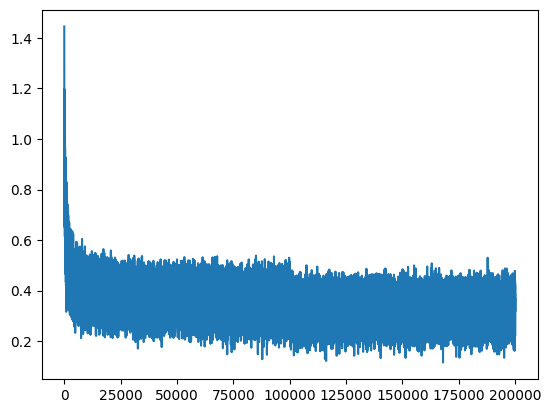

In [8]:
plt.plot(lossi)

In [9]:
@torch.no_grad()          # This decorator disables gradient tracking *************************
def split_loss(split: str):

  x, y = {
      'train': (Xtr, Ytr),
      'va;': (Xdev, Ydev),
      'test': (Xte, Yte)
  }[split]

  emb = C[x]

  embcat = emb.view(emb.shape[0], -1)
  h = torch.tanh(embcat @ W1 + b1)

  logits = h @ W2 + b2

  loss = F.cross_entropy(logits, y)
  print(f'{split}: {loss:.4f}')

split_loss('train')
split_loss('test')

train: 2.1277
test: 2.1674


In [10]:

# @torch.no_grad()          # This decorator disables gradient tracking ************************************ imp.
# Whatever happens in this function is assumed by torch to never required any gradients
# so it will not do any of the book-keeping that it does normally to keep the track of all the gradients
# in anticipation of an eventual backward pass
# all the tensor that get created here have the required_grad = False
# This save is memory and computational power at the backend


In [11]:
# Sample from the model
# Lets try creating new words using our model

g = torch.Generator().manual_seed(2147482647 + 10)

for _ in range(20):

  out = []
  context = [0]*block_size

  while True:
    # forward pass
    emb = C[torch.tensor(context)]
    embcat = emb.view(1, -1)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2

    probs = F.softmax(logits, dim = 1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    context = context[1:] + [ix]
    out.append(ix)

    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

nyendiq.
utzaen.
edeno.
neleena.
cornebe.
jny.
osdaci.
bhaun.
jhanko.
azjuniah.
dynn.
dhaizia.
rylinna.
mizier.
cornett.
hastynslei.
azrielee.
haylah.
nikoriana.
krianyn.


In [12]:
# At initilization all 27 char are equally likely output
# so the initial probality for each char should be 1/27
# initial probality distribution should be linear
# from that we can calculate the loss which is -log likelihood

In [14]:
# Expected initial loss

-torch.tensor(1/27.0).log()

tensor(3.2958)

In [15]:
# this is much much lower that   0/200000: 27.8817

In [19]:
# 4D example
logits = torch.tensor([0.0, 0.0, 0.0, 0.0])
probs = torch.softmax(logits, dim=0)
loss = -probs[2].log()
probs, loss

(tensor([0.2500, 0.2500, 0.2500, 0.2500]), tensor(1.3863))

In [22]:
# Manupulating the logits ----> can results in change in loss

In [21]:
# 4D example
logits = torch.tensor([-3.0, 10.0, 0.0, 4.0]) * 10
probs = torch.softmax(logits, dim=0)
loss = -probs[2 ].log()
probs, loss

(tensor([0.0000e+00, 1.0000e+00, 3.7835e-44, 8.7565e-27]), tensor(99.9831))

In [27]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g)
b2 = torch.randn(vocab_size, generator=g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i}/{max_step}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break

0/200000: 27.8817


In [28]:
logits[0]

tensor([ -2.3527,  36.4366, -10.7306,   5.7165,  18.6409, -11.6998,  -2.1991,
          1.8535,  10.9996,  10.6730,  12.3507, -10.3809,   4.7243, -24.4257,
         -8.5909,   1.9024, -12.2744, -12.4751, -23.2778,  -2.0163,  25.8767,
         14.2108,  17.7691, -10.9204, -20.7335,   6.4560,  11.1615],
       grad_fn=<SelectBackward0>)

In [29]:
# logits have extream value difference

# this logits should be close to zero

In [30]:
# logits = h @ W2 + b2

# 1
# because we want roughly zero, we dont want to be adding bias of random numbers
# thus, we will do
# b2 = torch.randn(vocab_size, generator=g) * 0
# initially the bias is zero

# 2
# we want close to zero logits therefore
# we want smaller number in W2
# thus
# W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.1

In [32]:
# implementing above changes

n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01       #*******imp.
b2 = torch.randn(vocab_size, generator=g) * 0                      #*******imp.

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i}/{max_step}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break

0/200000: 3.3221


In [ ]:
# roughly we want tensor(3.2958)
# -torch.tensor(1/27.0).log()

In [33]:
# implementing above changes

n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01       #*******imp.
b2 = torch.randn(vocab_size, generator=g) * 0                      #*******imp.

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

0/200000: 3.3221
10000/200000: 2.1900
20000/200000: 2.4196
30000/200000: 2.6067
40000/200000: 2.0601
50000/200000: 2.4988
60000/200000: 2.3902
70000/200000: 2.1344
80000/200000: 2.3369
90000/200000: 2.1299
100000/200000: 1.8329
110000/200000: 2.2053
120000/200000: 1.8540
130000/200000: 2.4566
140000/200000: 2.1879
150000/200000: 2.1118
160000/200000: 1.8956
170000/200000: 1.8644
180000/200000: 2.0326
190000/200000: 1.8417


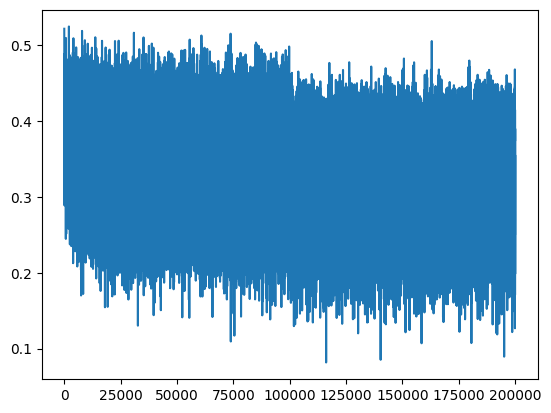

In [34]:
plt.plot(lossi)

In [35]:
split_loss('train')
split_loss('test')

train: 2.0696
test: 2.1328


In [36]:
# Sample from the model
# Lets try creating new words using our model

g = torch.Generator().manual_seed(2147482647 + 10)

for _ in range(20):

  out = []
  context = [0]*block_size

  while True:
    # forward pass
    emb = C[torch.tensor(context)]
    embcat = emb.view(1, -1)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2

    probs = F.softmax(logits, dim = 1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    context = context[1:] + [ix]
    out.append(ix)

    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

nyeed.
quin.
hender.
holo.
anessaccenebe.
jna.
osdellenhaunushankeea.
junix.
addan.
dhara.
sar.
azing.
mizie.
aziranti.
has.
diseli.
azrielee.
heylah.
nikoliana.
kriszynsleia.


In [40]:
# there is a problem with h

(array([79.,  4.,  1.,  0.,  3.,  0.,  0.,  2.,  0.,  1.,  0.,  0.,  0.,
         0.,  0.,  2.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,
         0.,  0.,  0.,  0.,  2.,  0.,  0.,  0.,  0.,  1.,  2.,  2.,  2.,
         0.,  1.,  0.,  1.,  0.,  0.,  0.,  2.,  3.,  5., 85.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

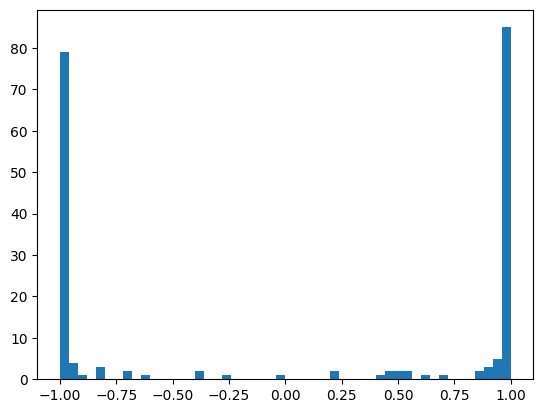

In [39]:
plt.hist(h.view(-1).tolist(), 50)

In [41]:
# implementing above changes

n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01       #*******imp.
b2 = torch.randn(vocab_size, generator=g) * 0                      #*******imp.

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i}/{max_step}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break

0/200000: 3.3221


In [43]:
h.shape

torch.Size([32, 200])

(array([2069.,  144.,  106.,   82.,   59.,   56.,   44.,   30.,   43.,
          26.,   16.,   38.,   16.,   32.,   24.,   14.,   28.,   27.,
          26.,   19.,   24.,   26.,   30.,   14.,   19.,   19.,   22.,
          26.,   18.,   12.,   10.,   33.,   27.,   32.,   17.,   24.,
          30.,   22.,   26.,   29.,   26.,   40.,   29.,   41.,   49.,
          64.,   62.,  100.,  188., 2442.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

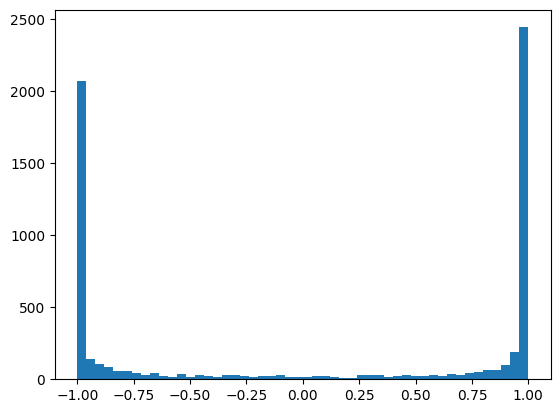

In [44]:
plt.hist(h.view(-1).tolist(), 50)

In [46]:
# Lot of values are '1' or '-1' in 'h'
# this is not good for us because
# grad will be zero - no optimization

# self.grad = (1 - t**2) * out.grad
# if t = 1 or t = -1 then grad=0

# def tanh(self):
#     x = self.data
#     t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
#     out = Value(t, (self,), "tanh")

#     def _backward():
#       self.grad = (1 - t**2) * out.grad

#     out._backward = _backward
#     return out

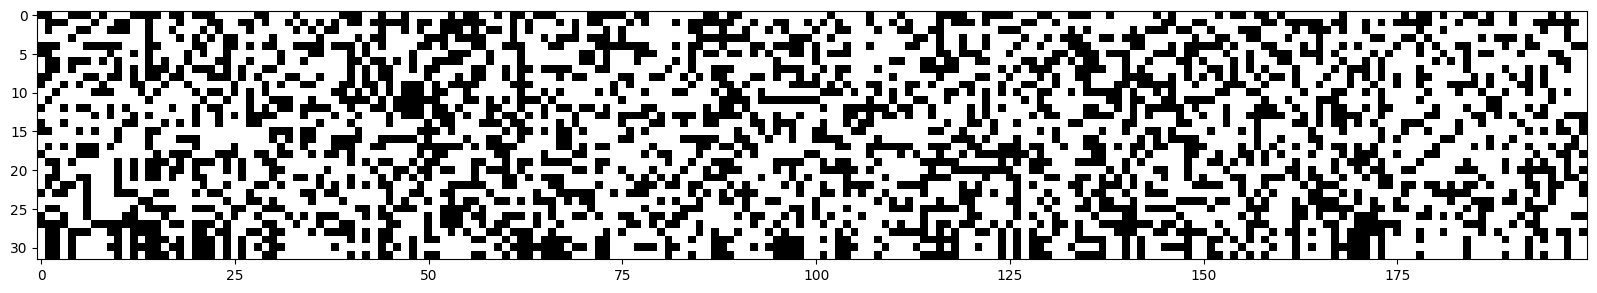

In [47]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99 , cmap = 'gray', interpolation='nearest')

In [48]:
# lot of whit inticates h.abs() > 0.99
# which will result in grad = 0

# NOTE:
# if whole column is white then that means that particular neuron will not activate
# i.e its a dead neuron
# in our case there are no dead neurons

In [49]:
# Why grad = 0 bad?
# if grad = 0 then we cant optimize that parameter parameter

(array([  2.,   2.,   1.,   4.,   2.,   4.,   6.,  15.,   5.,  25.,  32.,
         49.,  56.,  59.,  92., 119., 134., 197., 195., 221., 257., 275.,
        297., 341., 353., 375., 369., 349., 358., 362., 271., 312., 229.,
        206., 190., 167.,  87., 111.,  72.,  55.,  41.,  22.,  23.,  18.,
         17.,   8.,   5.,   7.,   2.,   1.]),
 array([-19.05793571, -18.31571732, -17.57349892, -16.83128052,
        -16.08906212, -15.34684372, -14.60462532, -13.86240692,
        -13.12018852, -12.37797012, -11.63575172, -10.89353333,
        -10.15131493,  -9.40909653,  -8.66687813,  -7.92465973,
         -7.18244133,  -6.44022293,  -5.69800453,  -4.95578613,
         -4.21356773,  -3.47134933,  -2.72913094,  -1.98691254,
         -1.24469414,  -0.50247574,   0.23974266,   0.98196106,
          1.72417946,   2.46639786,   3.20861626,   3.95083466,
          4.69305305,   5.43527145,   6.17748985,   6.91970825,
          7.66192665,   8.40414505,   9.14636345,   9.88858185,
         10.630800

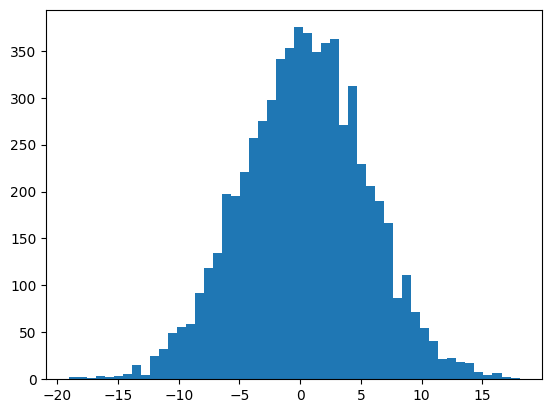

In [50]:
plt.hist(hpreact.view(-1).tolist(), 50)

In [51]:
# hpreact is too faar off from zero that is want causing this issue

In [56]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * 0.2     #*******imp.
b1 = torch.randn(n_hidden, generator=g) * 0.01                          #*******imp.

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i}/{max_step}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break

0/200000: 3.3135


(array([143., 172., 172., 161., 142., 151., 133., 116., 116., 143.,  95.,
        104., 126., 111., 119.,  91.,  86.,  90., 115., 100., 112., 122.,
        111.,  77., 103., 119., 100., 106.,  91.,  90., 117., 114., 116.,
        115., 107., 131., 111., 109., 114., 118., 142., 127., 162., 169.,
        152., 197., 184., 192., 208., 198.]),
 array([-9.98924255e-01, -9.58988956e-01, -9.19053657e-01, -8.79118358e-01,
        -8.39183059e-01, -7.99247760e-01, -7.59312460e-01, -7.19377161e-01,
        -6.79441862e-01, -6.39506563e-01, -5.99571264e-01, -5.59635965e-01,
        -5.19700665e-01, -4.79765366e-01, -4.39830067e-01, -3.99894768e-01,
        -3.59959469e-01, -3.20024170e-01, -2.80088871e-01, -2.40153571e-01,
        -2.00218272e-01, -1.60282973e-01, -1.20347674e-01, -8.04123747e-02,
        -4.04770756e-02, -5.41776419e-04,  3.93935227e-02,  7.93288219e-02,
         1.19264121e-01,  1.59199420e-01,  1.99134719e-01,  2.39070019e-01,
         2.79005318e-01,  3.18940617e-01,  3.58875

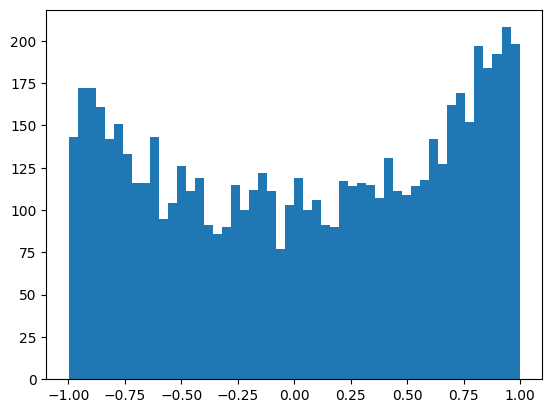

In [57]:
plt.hist(h.view(-1).tolist(), 50)

(array([  1.,   2.,   0.,   1.,   5.,   3.,  11.,   6.,  13.,  10.,  25.,
         40.,  40.,  77.,  63., 101., 127., 171., 184., 220., 227., 267.,
        312., 301., 356., 367., 376., 360., 370., 331., 298., 278., 292.,
        242., 191., 167., 137., 104.,  85.,  77.,  41.,  30.,  28.,  20.,
         11.,   7.,  11.,   5.,   2.,   7.]),
 array([-3.76367092, -3.62009715, -3.47652338, -3.33294961, -3.18937584,
        -3.04580207, -2.9022283 , -2.75865453, -2.61508076, -2.47150699,
        -2.32793322, -2.18435945, -2.04078568, -1.8972119 , -1.75363813,
        -1.61006436, -1.46649059, -1.32291682, -1.17934305, -1.03576928,
        -0.89219551, -0.74862174, -0.60504797, -0.4614742 , -0.31790043,
        -0.17432666, -0.03075289,  0.11282088,  0.25639465,  0.39996842,
         0.54354219,  0.68711596,  0.83068974,  0.97426351,  1.11783728,
         1.26141105,  1.40498482,  1.54855859,  1.69213236,  1.83570613,
         1.9792799 ,  2.12285367,  2.26642744,  2.41000121,  2.55357498,
 

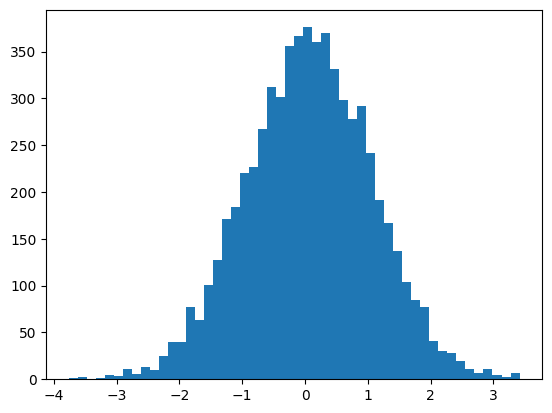

In [58]:
plt.hist(hpreact.view(-1).tolist(), 50)

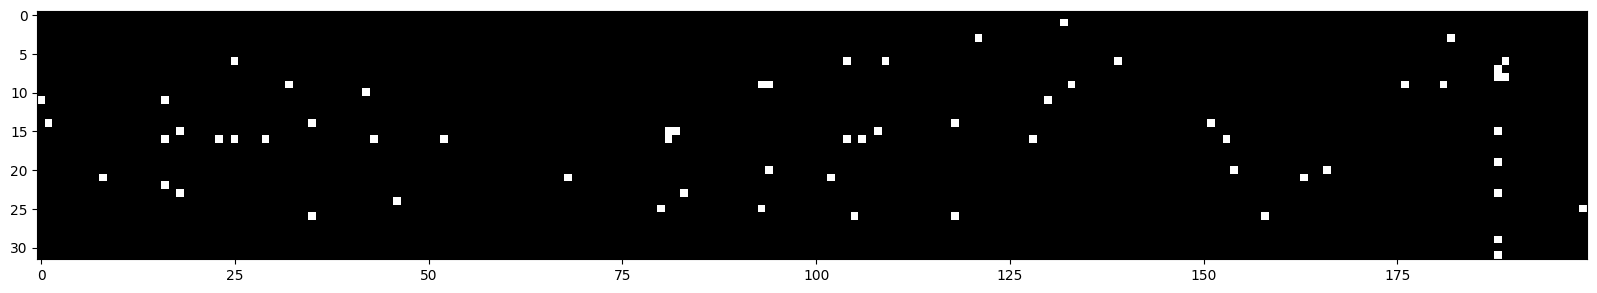

In [59]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99 , cmap = 'gray', interpolation='nearest')

In [60]:
# This is much better and preferable

In [62]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * 0.2     #*******imp.
b1 = torch.randn(n_hidden, generator=g) * 0.01                          #*******imp.

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3135
  10000/ 200000: 2.1648
  20000/ 200000: 2.3061
  30000/ 200000: 2.4541
  40000/ 200000: 1.9787
  50000/ 200000: 2.2930
  60000/ 200000: 2.4232
  70000/ 200000: 2.0680
  80000/ 200000: 2.3095
  90000/ 200000: 2.1207
 100000/ 200000: 1.8269
 110000/ 200000: 2.2045
 120000/ 200000: 1.9797
 130000/ 200000: 2.3946
 140000/ 200000: 2.1000
 150000/ 200000: 2.1948
 160000/ 200000: 1.8619
 170000/ 200000: 1.7809
 180000/ 200000: 1.9673
 190000/ 200000: 1.8295


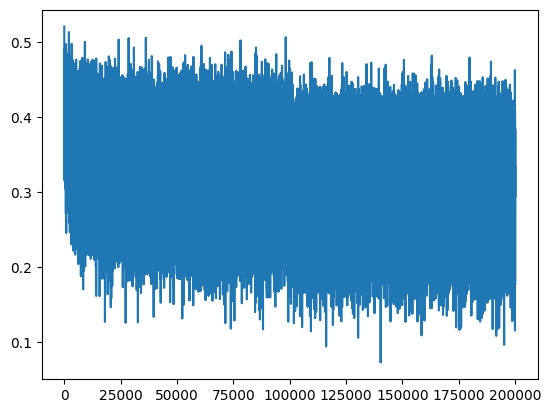

In [63]:
plt.plot(lossi)

In [64]:
split_loss('train')
split_loss('test')

train: 2.0356
test: 2.1012


In [65]:
# Sample from the model
# Lets try creating new words using our model

g = torch.Generator().manual_seed(2147482647 + 10)

for _ in range(20):

  out = []
  context = [0]*block_size

  while True:
    # forward pass
    emb = C[torch.tensor(context)]
    embcat = emb.view(1, -1)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2

    probs = F.softmax(logits, dim = 1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    context = context[1:] + [ix]
    out.append(ix)

    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

nyeldiquel.
hen.
ell.
ose.
leesham.
breki.
jna.
ospell.
bhilah.
hanko.
azaina.
janyann.
haiza.
kryn.
inn.
mizier.
coranti.
has.
dilee.
aly.


In [66]:
# 2 issues we had fixed

# 1. Softmax confidently wrong
# 2. tanh layer too saturated at init